# 01: Download data and add H&E images
Data from: 
- healthy: https://lamin.ai/scverse/spatialdata-db/artifact/OJh6O09BO0KvcaqQ0000
- disease: https://lamin.ai/scverse/spatialdata-db/artifact/6hNpuo8as4YTeuir0000

In [1]:
!lamin connect scverse/spatialdata-db

→ connected lamindb: scverse/spatialdata-db


In [2]:
import spatialdata as sd
import spatialdata_plot
import pandas as pd
from pathlib import Path
from spatialdata.models import Image2DModel
import matplotlib.pyplot as plt
import tifffile

from spatialdata.transformations import (
    Affine,
    Sequence,
)
import bionty as bt
import lamindb as ln

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/importlib/__init__.py:126: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  return _bootstrap._gcd_import(name[level:], package, level)


→ connected lamindb: scverse/spatialdata-db


In [4]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")

In [4]:
# Define Bionty lookups for autocomplete
organisms = bt.Organism.lookup()
tissues = bt.Tissue.lookup()

In [5]:
# Query for datasets we want
ln.Artifact.filter(
    organisms=organisms.human,
    tissues=tissues.breast,
    description__icontains="Xenium FFPE Healthy Human Breast (Tissue sample",
).df()

,uid,key,description,suffix,kind,otype,size,hash,n_files,n_observations,_hash_type,_key_is_virtual,_overwrite_versions,space_id,storage_id,schema_id,version,is_latest,run_id,created_at,created_by_id,_aux,_branch_code
id,,,,,,,,,,,,,,,,,,,,,,,
732,1lNcghy5uvSIIj1X0000,101x5.zarr,Xenium FFPE Healthy Human Breast (Tissue sampl...,.zarr,dataset,SpatialData,10988771641,tpqoZ0gzYnzK5BgZl8zvgQ,1390,None,md5-d,True,True,1,2,249,None,False,None,2025-05-12 22:49:08.234849+00:00,8,None,1
733,Uj7J4jjgzHw0lcm80000,10pf0.zarr,Xenium FFPE Healthy Human Breast (Tissue sampl...,.zarr,dataset,SpatialData,7226610339,K_I3rzp9ZpOdLPehaaMLCQ,1066,None,md5-d,True,True,1,2,249,None,False,None,2025-05-12 22:52:11.061608+00:00,8,None,1
803,1lNcghy5uvSIIj1X0001,101x5.zarr,Xenium FFPE Healthy Human Breast (Tissue sampl...,.zarr,dataset,SpatialData,10988771641,ng9uKUIW4wf1OVVS4ptnkg,1390,None,md5-d,True,True,1,2,249,None,True,None,2025-05-13 11:51:03.364394+00:00,8,None,1
804,Uj7J4jjgzHw0lcm80001,10pf0.zarr,Xenium FFPE Healthy Human Breast (Tissue sampl...,.zarr,dataset,SpatialData,7226610339,1LyAYDg2RQzRro8VU9NweQ,1066,None,md5-d,True,True,1,2,249,None,True,None,2025-05-13 11:54:55.669684+00:00,8,None,1


In [6]:
sdata_sample1 = ln.Artifact.get("1lNcghy5uvSIIj1X0001").load()
sdata_sample2 = ln.Artifact.get("Uj7J4jjgzHw0lcm80001").load()

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)


! run input wasn't tracked, call `ln.track()` and re-run


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)


! run input wasn't tracked, call `ln.track()` and re-run


In [38]:
sdata_sample1

SpatialData object, with associated Zarr store: /ictstr01/home/icb/tim.treis/.cache/lamindb/scverse-spatial-eu-central-1/101x5.zarr
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 53833, 48441), (1, 26916, 24220), (1, 13458, 12110), (1, 6729, 6055), (1, 3364, 3027)
│     └── 'morphology_mip': DataTree[cyx] (1, 53833, 48441), (1, 26916, 24220), (1, 13458, 12110), (1, 6729, 6055), (1, 3364, 3027)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
│     └── 'nucleus_labels': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (574527, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (574527, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (574527, 1) (2D shapes)
└── Tables
      └── 'table': AnnDat

INFO     Rasterizing image for faster rendering.                                                                   


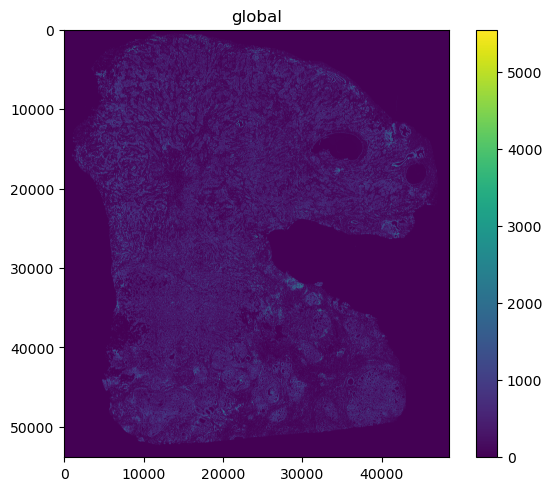

In [39]:
sdata_sample1.pl.render_images("morphology_focus").pl.show()

In [40]:
sdata_sample2

SpatialData object, with associated Zarr store: /ictstr01/home/icb/tim.treis/.cache/lamindb/scverse-spatial-eu-central-1/10pf0.zarr
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 41411, 45749), (1, 20705, 22874), (1, 10352, 11437), (1, 5176, 5718), (1, 2588, 2859)
│     └── 'morphology_mip': DataTree[cyx] (1, 41411, 45749), (1, 20705, 22874), (1, 10352, 11437), (1, 5176, 5718), (1, 2588, 2859)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
│     └── 'nucleus_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (365604, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (365604, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (365604, 1) (2D shapes)
└── Tables
      └── 'table': AnnDat

INFO     Rasterizing image for faster rendering.                                                                   


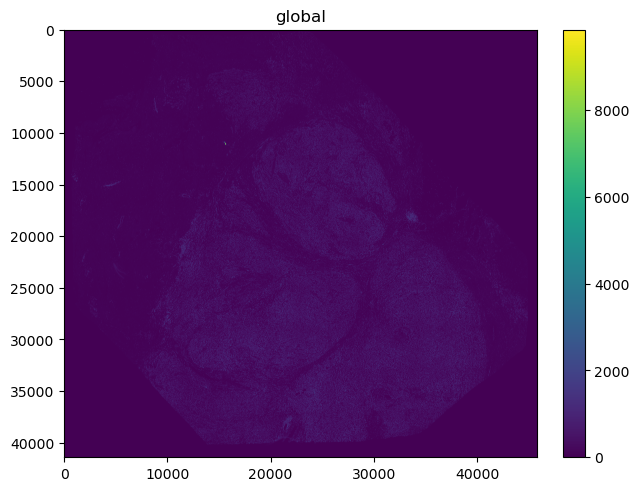

In [41]:
sdata_sample2.pl.render_images("morphology_focus").pl.show()

## Get H&E for the datasets

In [45]:
# get source link

sdata_sample1.attrs["metadata_general"]["Dataset Url"]

'https://www.10xgenomics.com/datasets/ffpe-human-breast-with-custom-add-on-panel-1-standard'

In [48]:
# sample 1
!curl -O https://cf.10xgenomics.com/samples/xenium/1.0.2/Xenium_V1_FFPE_Human_Breast_IDC_With_Addon/Xenium_V1_FFPE_Human_Breast_IDC_With_Addon_he_unaligned_image.ome.tif
!curl -O https://cf.10xgenomics.com/samples/xenium/1.0.2/Xenium_V1_FFPE_Human_Breast_IDC_With_Addon/Xenium_V1_FFPE_Human_Breast_IDC_With_Addon_he_imagealignment.csv

# sample 2
!curl -O https://cf.10xgenomics.com/samples/xenium/1.0.2/Xenium_V1_FFPE_Human_Breast_ILC_With_Addon/Xenium_V1_FFPE_Human_Breast_ILC_With_Addon_he_unaligned_image.ome.tif
!curl -O https://cf.10xgenomics.com/samples/xenium/1.0.2/Xenium_V1_FFPE_Human_Breast_ILC_With_Addon/Xenium_V1_FFPE_Human_Breast_ILC_With_Addon_he_imagealignment.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 3749M  100 3749M    0     0  22.4M      0  0:02:46  0:02:46 --:--:-- 39.7M
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   127  100   127    0     0    224      0 --:--:-- --:--:-- --:--:--   223
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 2877M  100 2877M    0     0   258M      0  0:00:11  0:00:11 --:--:--  268M
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   127  100   127    0     0    218      0 --:--:-- --:--:-- --:--:--   218


In [8]:
sample1_img_path = Path("./Xenium_V1_FFPE_Human_Breast_IDC_With_Addon_he_unaligned_image.ome.tif")
sample2_img_path = Path("./Xenium_V1_FFPE_Human_Breast_ILC_With_Addon_he_unaligned_image.ome.tif")

In [9]:
img1 = tifffile.imread(sample1_img_path)
img2 = tifffile.imread(sample2_img_path)

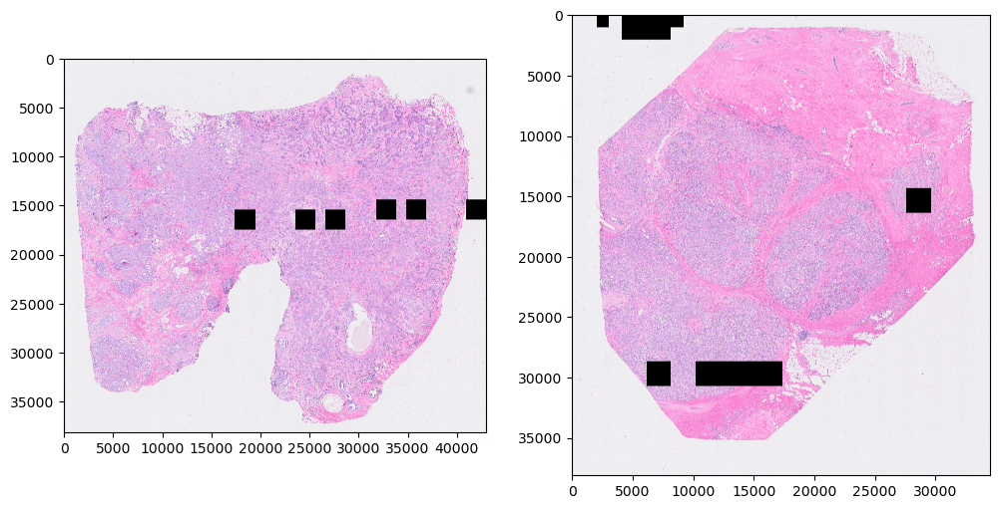

In [54]:
fig, axs =  plt.subplots(ncols=2, nrows=1, figsize=(12, 6))

axs[0].imshow(img1)
axs[1].imshow(img2)

Okay, some corrupted squares but whatever I guess

In [17]:
sample1_affine_mat = pd.read_csv("./Xenium_V1_FFPE_Human_Breast_IDC_With_Addon_he_imagealignment.csv", header=None).values
sample2_affine_mat = pd.read_csv("./Xenium_V1_FFPE_Human_Breast_ILC_With_Addon_he_imagealignment.csv", header=None).values

In [18]:
# details: https://spatialdata.scverse.org/en/latest/tutorials/notebooks/notebooks/examples/transformations.html

H, W = img1.shape[0], img1.shape[1]

rot_cw = Affine(
    [
        # [ cos(-90°)=0, -sin(-90°)=1, tx=0 ]
        # [ sin(-90°)=-1, cos(-90°)=0, ty=H ]
        [ 0,  1,    0 ],
        [-1,  0,    H ],
        [ 0,  0,    1 ],
    ],
    input_axes = ("x", "y"),
    output_axes = ("x", "y"),
)

flip_vert = Affine(
    [
        [1,  0,   0 ],   # x stays
        [0, -1,   H ],   # y-> −y then +H
        [0,  0,   1 ],
    ],
    input_axes = ("x","y"),
    output_axes = ("x","y"),
)


sample1_sequence = Sequence([
    rot_cw,
    flip_vert,
    Affine(sample1_affine_mat, input_axes=("x","y"), output_axes=("x","y")),
])
# set_transformation(sdata.images["raw_image"], rotation, to_coordinate_system="global")

In [19]:
sdata_sample1.images["hne"] = Image2DModel.parse(
    img1.transpose(2, 1, 0), # (x, y, z) -> (c, y, x)
    transformations={"global": sample1_sequence},
    scale_factors=[2, 2, 2]
)

INFO     no axes information specified in the object, setting `dims` to: ('c', 'y', 'x')                           


INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


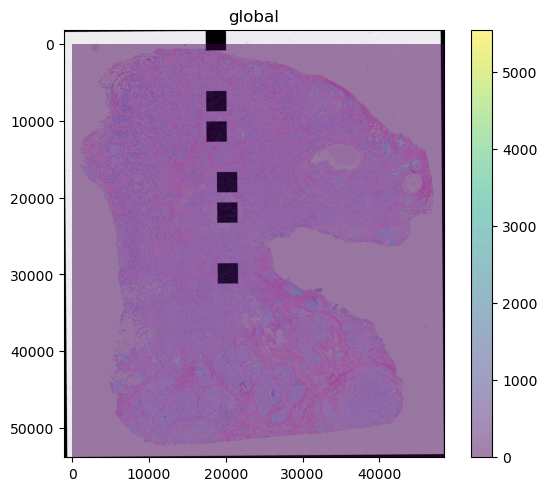

In [20]:
(
    sdata_sample1
    .pl.render_images("hne", alpha=1)
    .pl.render_images("morphology_focus", alpha=.5)
    # .pl.render_labels("cell_labels", fill_alpha=0)
    .pl.show()
)

In [21]:
sdata_sample1.write(data_dir / "xenium_sample1.zarr", overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1.zarr).      
         Please see the documentation of `is_self_contained()` to understand the implications of working with      
         SpatialData objects that are not self-contained.                                                          
INFO     The Zarr backing store has been changed from                                                              
         /home/icb/tim.treis/.cache/lamindb/scverse-spatial-eu-central-1/101x5.zarr the new file path:             
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1.zarr                          


In [84]:
sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


In [91]:
(
    sdata_sample1
    .pl.render_images("hne", alpha=1)
    .pl.render_images("morphology_focus", alpha=.5)
    .pl.render_labels("cell_labels", fill_alpha=0)
    .pl.show(figsize=(20, 20))
)

INFO     Rasterizing image for faster rendering.                                                                   


INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


In [11]:
H, W = img2.shape[0], img2.shape[1]

rot_cw = Affine(
    [
        # [ cos(-90°)=0, -sin(-90°)=1, tx=0 ]
        # [ sin(-90°)=-1, cos(-90°)=0, ty=H ]
        [ 0,  1,    0 ],
        [-1,  0,    H ],
        [ 0,  0,    1 ],
    ],
    input_axes = ("x", "y"),
    output_axes = ("x", "y"),
)

flip_vert = Affine(
    [
        [1,  0,   0 ],   # x stays
        [0, -1,   H ],   # y-> −y then +H
        [0,  0,   1 ],
    ],
    input_axes = ("x","y"),
    output_axes = ("x","y"),
)


sample2_sequence = Sequence([
    rot_cw,
    flip_vert,
    Affine(sample2_affine_mat, input_axes=("x","y"), output_axes=("x","y")),
])

In [12]:
sdata_sample2.images["hne"] = Image2DModel.parse(
    img2.transpose(2, 1, 0), # (x, y, z) -> (c, y, x)
    transformations={"global": sample2_sequence},
    scale_factors=[2, 2, 2]
)

INFO     no axes information specified in the object, setting `dims` to: ('c', 'y', 'x')                           


INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


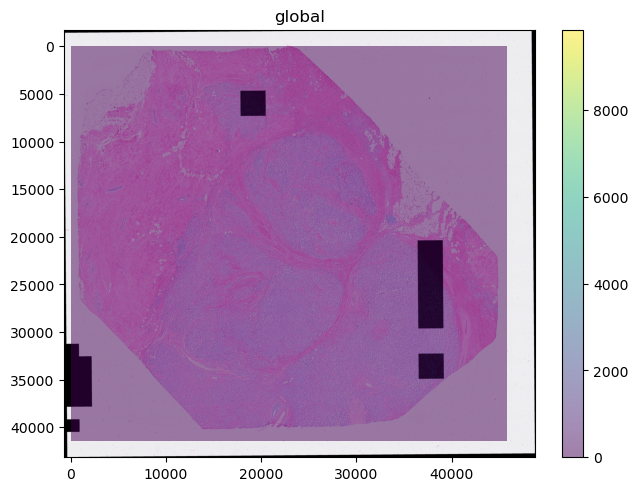

In [13]:
(
    sdata_sample2
    .pl.render_images("hne", alpha=1)
    .pl.render_images("morphology_focus", alpha=.5)
    .pl.show() # figsize=(20, 20))
)

In [14]:
sdata_sample2.write(data_dir / "xenium_sample2.zarr", overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2.zarr).      
         Please see the documentation of `is_self_contained()` to understand the implications of working with      
         SpatialData objects that are not self-contained.                                                          
INFO     The Zarr backing store has been changed from                                                              
         /home/icb/tim.treis/.cache/lamindb/scverse-spatial-eu-central-1/10pf0.zarr the new file path:             
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2.zarr                          


In [5]:
sdata_sample2 = sd.read_zarr(data_dir / "xenium_sample2.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


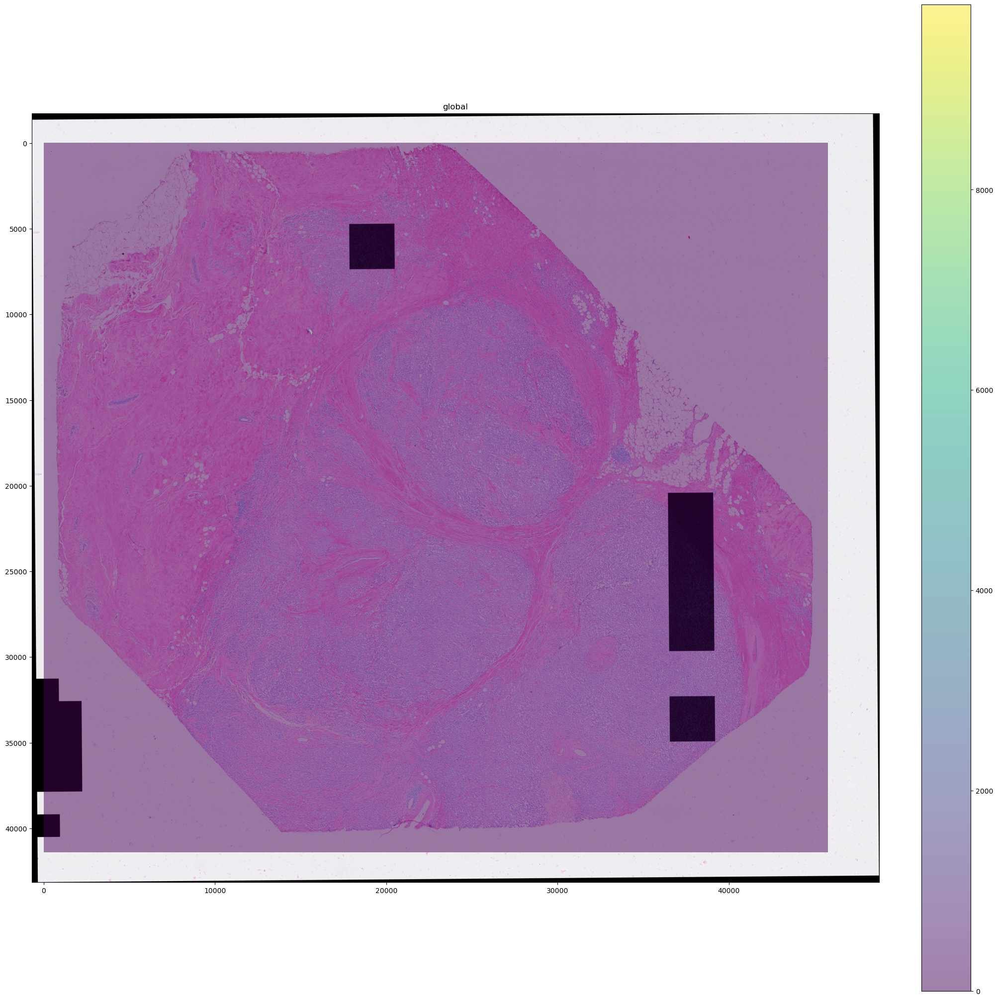

In [6]:
(
    sdata_sample2
    .pl.render_images("hne", alpha=1)
    .pl.render_images("morphology_focus", alpha=.5)
    .pl.show(figsize=(20, 20))
)

In [24]:
sdata_sample2

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2.zarr
├── Images
│     ├── 'hne': DataTree[cyx] (3, 34537, 38096), (3, 17268, 19048), (3, 8634, 9524), (3, 4317, 4762)
│     ├── 'morphology_focus': DataTree[cyx] (1, 41411, 45749), (1, 20705, 22874), (1, 10352, 11437), (1, 5176, 5718), (1, 2588, 2859)
│     └── 'morphology_mip': DataTree[cyx] (1, 41411, 45749), (1, 20705, 22874), (1, 10352, 11437), (1, 5176, 5718), (1, 2588, 2859)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
│     └── 'nucleus_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (365604, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (365604, 2) (2D shapes)
│     └── '

## Bake in the transformation so we can calculate on it

Problem:
- The H&E is only visually aligned
- For the morphology function, the label and img need to have the same shape (needs to be fixed)
- So we need to bake in the affine transformation we just added
- For that, we'll transform the image and then crop away the black pixels at the edge s

In [4]:
sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1_subset.zarr")
sdata_sample1

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_subset.zarr
├── Images
│     ├── 'hne': DataTree[cyx] (3, 42947, 38096), (3, 21473, 19048), (3, 10736, 9524), (3, 5368, 4762)
│     ├── 'morphology_focus': DataTree[cyx] (1, 53833, 48441), (1, 26916, 24220), (1, 13458, 12110), (1, 6729, 6055), (1, 3364, 3027)
│     └── 'morphology_mip': DataTree[cyx] (1, 53833, 48441), (1, 26916, 24220), (1, 13458, 12110), (1, 6729, 6055), (1, 3364, 3027)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
│     ├── 'cell_labels_subset': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
│     └── 'nucleus_labels': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries

In [5]:
sdata_sample1.images["hne_baked"] = sd.transform(sdata_sample1.images["hne"], to_coordinate_system="global")
sdata_sample1

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_subset.zarr
├── Images
│     ├── 'hne': DataTree[cyx] (3, 42947, 38096), (3, 21473, 19048), (3, 10736, 9524), (3, 5368, 4762)
│     ├── 'hne_baked': DataTree[cyx] (3, 55732, 49529), (3, 27865, 24764), (3, 13932, 12382), (3, 6966, 6191)
│     ├── 'morphology_focus': DataTree[cyx] (1, 53833, 48441), (1, 26916, 24220), (1, 13458, 12110), (1, 6729, 6055), (1, 3364, 3027)
│     └── 'morphology_mip': DataTree[cyx] (1, 53833, 48441), (1, 26916, 24220), (1, 13458, 12110), (1, 6729, 6055), (1, 3364, 3027)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
│     ├── 'cell_labels_subset': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
│     └── 'nucleus_labels': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
├── Points
│

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


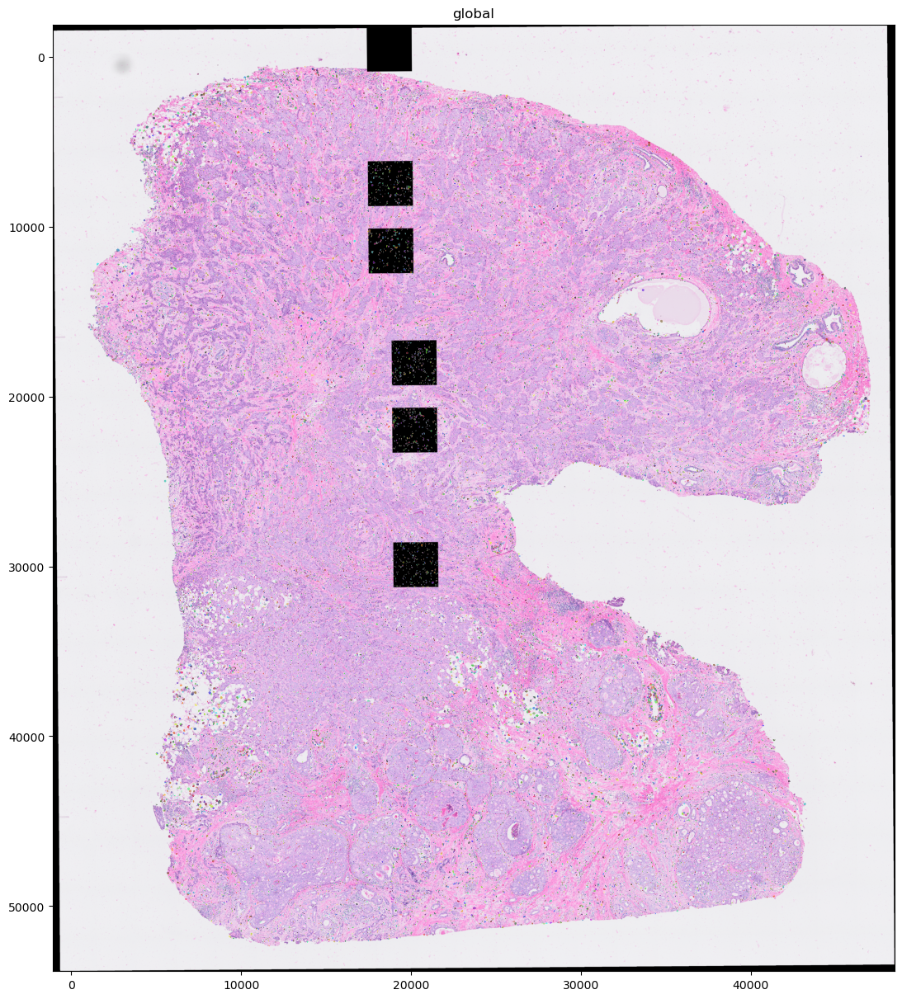

In [6]:
# visually decide where we crop
(
    sdata_sample1
    .pl.render_images("hne_baked")
    .pl.render_labels("cell_labels_subset")
    .pl.show(figsize=(12, 12))
)


In [18]:
sdata_sample1["hne_baked"] = sdata_sample1["hne_baked"].chunk({"y": 4096, "x": 4096})

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata/_core/_elements.py:71: UserWarning: Key `hne_baked` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


In [19]:
sdata_sample1.write(data_dir / "xenium_sample1_subset_baked.zarr", overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_subset_baked.zarr). Please see
         the documentation of `is_self_contained()` to understand the implications of working with SpatialData     
         objects that are not self-contained.                                                                      
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_subset.zarr the new file path:
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_subset_baked.zarr             


In [20]:
sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1_subset_baked.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


In [21]:
max_y, max_x = sdata_sample1.labels["cell_labels_subset"]["scale0"].image.shape

In [25]:
# we can probably just crop to the dimensions of the labels img since the transformation rotated it into the negative

sdata_sample1_crop = sdata_sample1.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[1000, 1000],
    max_coordinate=[max_x-1000, max_y-1000],
    target_coordinate_system="global",
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


In [26]:
sdata_sample1_crop

SpatialData object
├── Images
│     ├── 'hne': DataTree[cyx] (3, 40497, 36347), (3, 20249, 18174), (3, 10124, 9086), (3, 5062, 4544)
│     ├── 'hne_baked': DataTree[cyx] (3, 51833, 46441), (3, 25916, 23220), (3, 12957, 11610), (3, 6479, 5805)
│     ├── 'morphology_focus': DataTree[cyx] (1, 51833, 46441), (1, 25916, 23220), (1, 12958, 11610), (1, 6479, 5805), (1, 3240, 2903)
│     └── 'morphology_mip': DataTree[cyx] (1, 51833, 46441), (1, 25916, 23220), (1, 12958, 11610), (1, 6479, 5805), (1, 3240, 2903)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (51833, 46441), (25916, 23220), (12958, 11610), (6479, 5805), (3240, 2903)
│     ├── 'cell_labels_subset': DataTree[yx] (51833, 46441), (25916, 23220), (12958, 11610), (6479, 5805), (3240, 2903)
│     └── 'nucleus_labels': DataTree[yx] (51833, 46441), (25916, 23220), (12958, 11610), (6479, 5805), (3240, 2903)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDat

In [27]:
del sdata_sample1_crop["hne"]

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


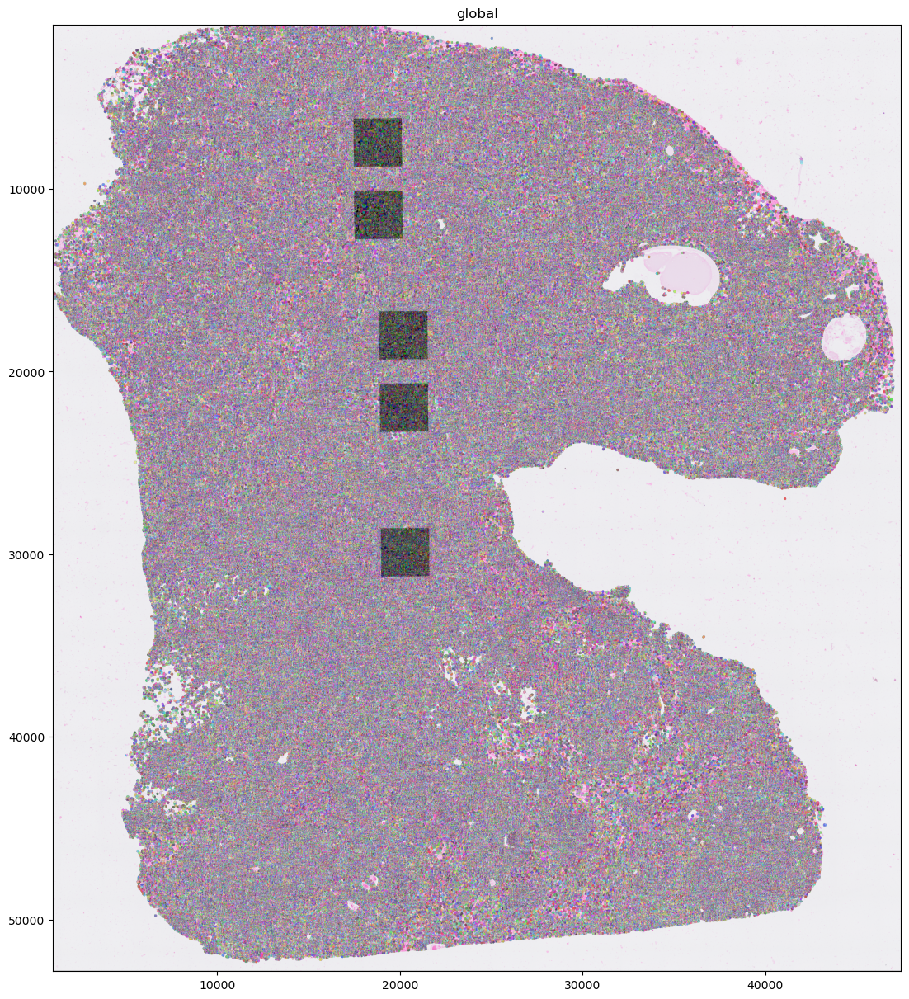

In [28]:
sdata_sample1_crop.pl.render_images("hne_baked").pl.render_labels("cell_labels").pl.show(figsize=(12, 12))

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


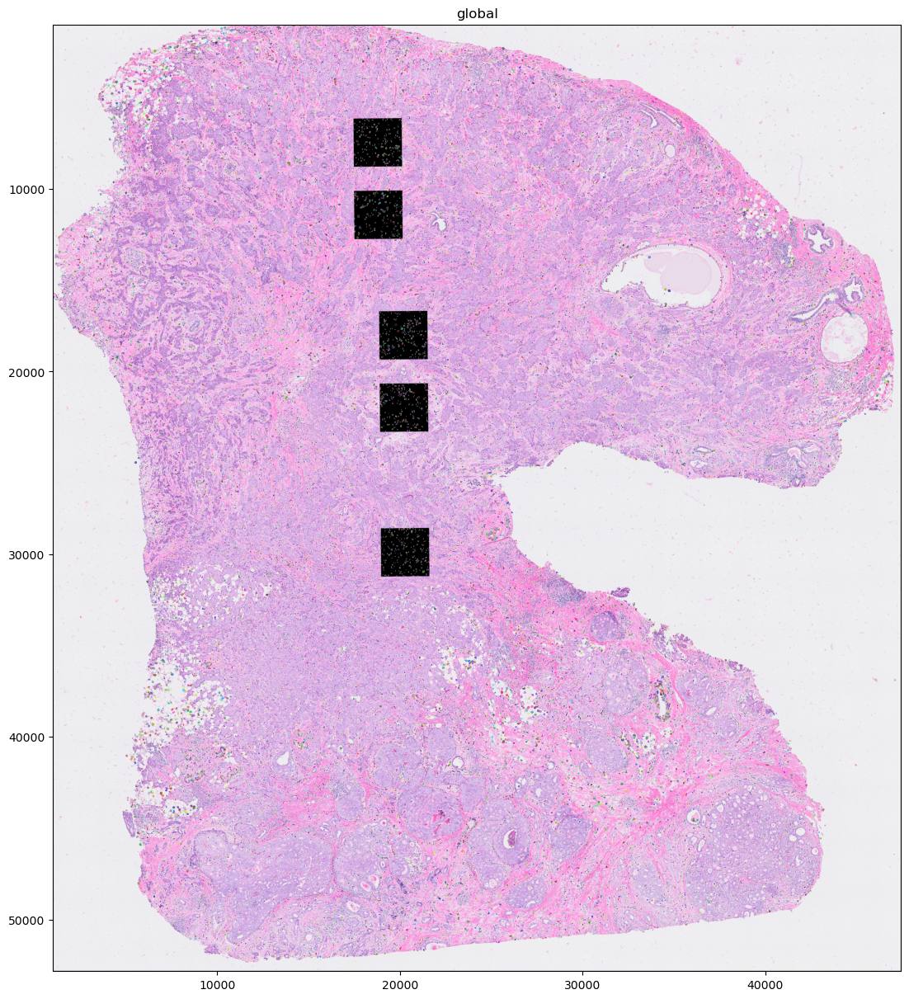

In [33]:
sdata_sample1_crop.pl.render_images("hne_baked").pl.render_labels("cell_labels_subset").pl.show(figsize=(12, 12))

aligned, fuck yeah

In [29]:
sdata_sample1_crop.write(data_dir / "xenium_sample1_subset_baked_cropped.zarr", overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_subset_baked_cropped.zarr).   
         Please see the documentation of `is_self_contained()` to understand the implications of working with      
         SpatialData objects that are not self-contained.                                                          
INFO     The Zarr backing store has been changed from None the new file path:                                      
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_subset_baked_cropped.zarr     


### Let's repeat for sample 2

In [7]:
sdata_sample2 = sd.read_zarr(data_dir / "xenium_sample2_subset.zarr")
sdata_sample2.images["hne_baked"] = sd.transform(sdata_sample2.images["hne"], to_coordinate_system="global")
max_y, max_x = sdata_sample2.labels["cell_labels_subset"]["scale0"].image.shape

sdata_sample2_crop = sdata_sample2.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[0, 0],
    max_coordinate=[max_x, max_y],
    target_coordinate_system="global",
)

del sdata_sample2_crop["hne"]

sdata_sample2_crop.write(data_dir / "xenium_sample2_subset_baked_cropped.zarr", overwrite=True)

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_subset_baked_cropped.zarr).   
         Please see the documentation of `is_self_contained()` to understand the implications of working with      
         SpatialData objects that are not self-contained.                                                          
INFO     The Zarr backing store has been changed from None the new file path:                                      
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_subset_baked_cropped.zarr     


In [ ]:
sdata_sample2_crop.write(data_dir / "xenium_sample2_subset_baked_cropped.zarr", overwrite=True)

In [ ]:
sdata_sample1["hne_baked"] = sdata_sample1["hne_baked"].chunk({"y": 4096, "x": 4096})

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


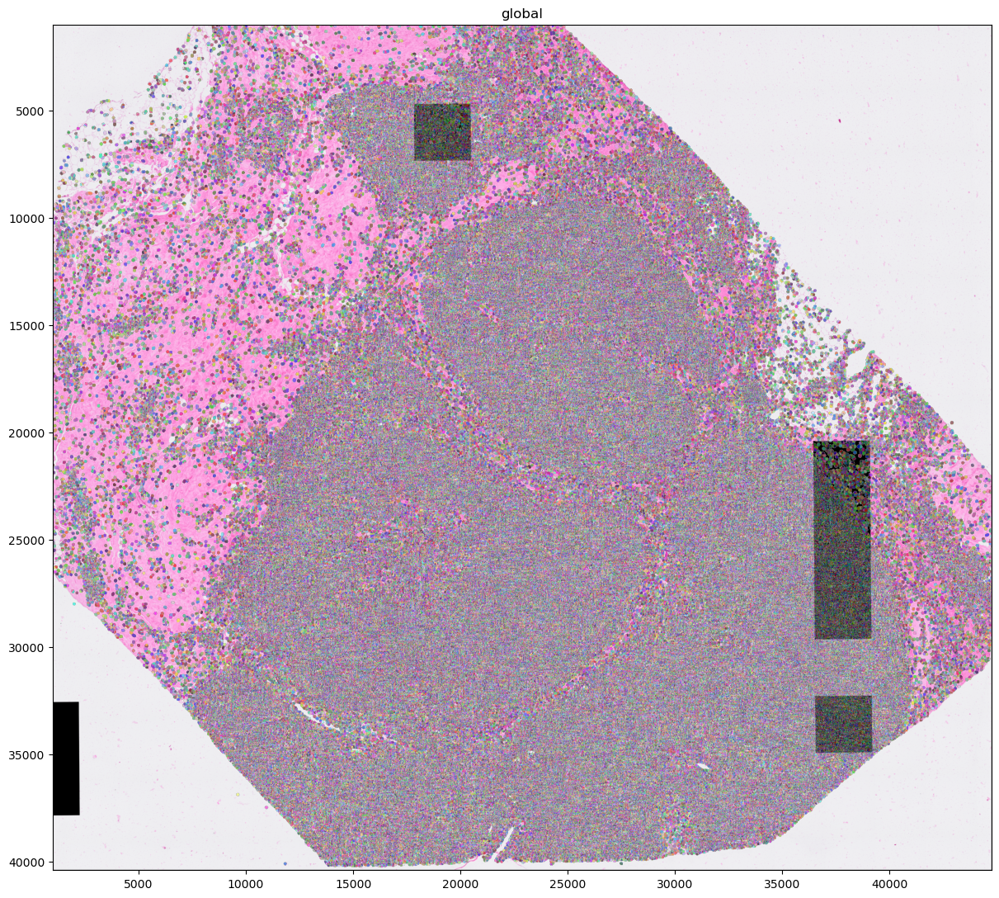

In [31]:
sdata_sample2_crop.pl.render_images("hne_baked").pl.render_labels("cell_labels").pl.show(figsize=(12, 12))

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   


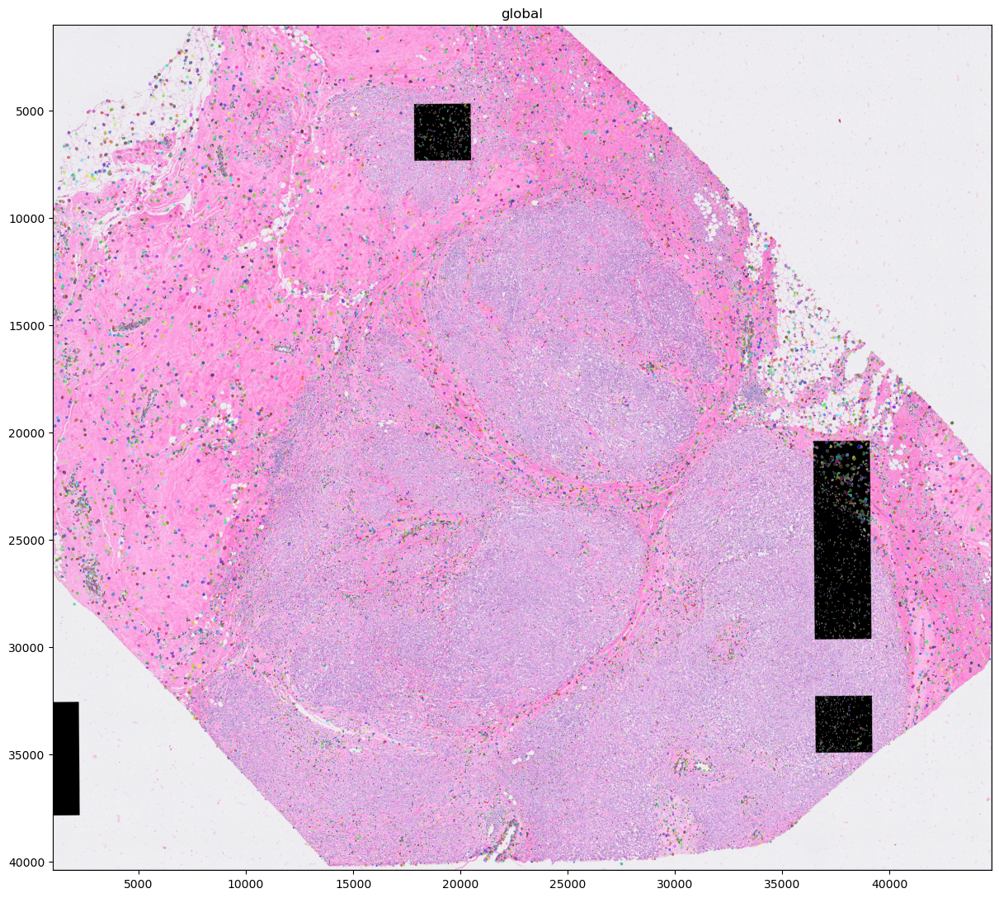

In [32]:
sdata_sample2_crop.pl.render_images("hne_baked").pl.render_labels("cell_labels_subset").pl.show(figsize=(12, 12))